<img src="https://miro.medium.com/v2/resize:fit:1400/0*dZkodxQqSsXyB_xV.png">

In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_groq import ChatGroq

In [2]:
llm = ChatGroq(
    model = "openai/gpt-oss-120b"
)

In [3]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [4]:
def chat_node(state: ChatState):

    # Take user query from State
    messages = state['messages']

    # Send to LLM
    response = llm.invoke(messages)

    # Response store state
    return {'messages': [response]}

In [5]:
graph = StateGraph(ChatState)

# Add Nodes
graph.add_node('Chat Node', chat_node)

# Add Edges
graph.add_edge(START, 'Chat Node')
graph.add_edge('Chat Node', END)

chatbot = graph.compile()

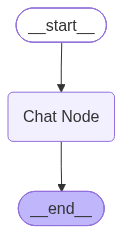

In [6]:
chatbot

In [7]:
initial_state = {
    'messages' : [HumanMessage(content = 'What are the Free LLM Models are available?')]
}

response = chatbot.invoke(initial_state)
response

{'messages': [HumanMessage(content='What are the Free LLM Models are available?', additional_kwargs={}, response_metadata={}, id='ed4d2568-4a3a-43d8-97f4-b7cbea6bd08b'),
  AIMessage(content='Below is a curated, up‑to‑date (Sept\u202f2026) snapshot of the **free‑to‑download / open‑source LLMs** that you can run yourself (or, in many cases, call through a free‑tier API).  \nI’ve grouped them by size, architecture, and primary use‑case, added licensing notes, and linked to the most common distribution points (Hugging\u202fFace, GitHub, model‑specific sites).\n\n---\n\n## 1️⃣ Quick‑look Table\n\n| Model | Architecture | Parameters | Release\u202fYear | License | Typical Use‑Case | Where to Get |\n|-------|--------------|------------|--------------|---------|------------------|--------------|\n| **Llama\u202f3‑8B / 70B** | Meta‑Llama‑3 (Mixture‑of‑Experts for 70B) | 8\u202fB / 70\u202fB | 2024 | Meta‑Llama\u202f3 Community License (non‑commercial, research, limited‑commercial) | 🤗\u202fHF: 

In [8]:
while True:
    user_message = input('Type here: ')
    print('User: ', user_message)
    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        print('AI: Thanks for the Visiting!')
        break
    response = chatbot.invoke({'messages': [HumanMessage(content = user_message)]})
    print('AI: ', response['messages'][-1].content)

User:  Hi, My Name is Aadhi
AI:  Hello Aadhi! 👋 Nice to meet you. How can I help you today?
User:  What is My Name?
AI:  I don’t actually know your name—unless you’ve shared it with me before in this conversation. If you’d like me to address you by name, just let me know what it is!
User:  Bye
AI: Thanks for the Visiting!


##### <i><b> Persistence in LangGraph
- Persistence in LangGraph is a built-in layer that automatically saves and restore the state of your agent or graph workflow over time.
- It works by using a checkpointer to automatically capyure snapshots of the graph's state at every step, organizing them into unique, retrievable threads.

In [11]:
from langgraph.checkpoint.memory import MemorySaver

In [12]:
checkpoint = MemorySaver()

graph = StateGraph(ChatState)

# Add Nodes
graph.add_node('Chat Node', chat_node)

# Add Edges
graph.add_edge(START, 'Chat Node')
graph.add_edge('Chat Node', END)

chatbot = graph.compile(checkpointer=checkpoint)

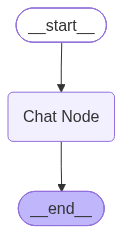

In [13]:
chatbot

In [14]:
thread_id = "1"

while True:
    user_message = input('Type here: ')
    print('User: ', user_message)
    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        print('AI: Thanks for the Visiting!')
        break

    config = {'configurable' : {'thread_id' : thread_id}}
    response = chatbot.invoke({'messages': [HumanMessage(content = user_message)]}, config = config)
    print('AI: ', response['messages'][-1].content)

User:  Hi, My Name is Aadhiseshan K S
AI:  Hello Aadhiseshan! Nice to meet you. How can I assist you today?
User:  What is your Name?
AI:  I’m ChatGPT, an AI language model created by OpenAI. How can I help you today?
User:  What is My Name?
AI:  Your name is **Aadhiseshan K S**. Let me know if there’s anything else you’d like to discuss!
User:  Bye
AI: Thanks for the Visiting!


In [15]:
chatbot.get_state(config = config)

StateSnapshot(values={'messages': [HumanMessage(content='Hi, My Name is Aadhiseshan K S', additional_kwargs={}, response_metadata={}, id='de465c69-8289-4011-9bcb-cb2cba2ef99a'), AIMessage(content='Hello Aadhiseshan! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': "User says hello, introduces themselves. We should respond politely, maybe ask how we can help. No special instructions. We'll respond friendly."}, response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 82, 'total_tokens': 137, 'completion_time': 0.116888496, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.003477879, 'prompt_tokens_details': None, 'queue_time': 0.311512255, 'total_time': 0.120366375}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_068241849b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a05b4e-c427-7cd1-a1a7-19758303e17c-0', tool_calls=[], in